# EDA — MVTec AD (hazelnut)

Faz 1: görüntü boyutları, normal/anormal oran, maske piksel dağılımı (class imbalance) analizi.

Bu notebook `src/prepare_data.py` tarafından üretilen `data/processed/splits.csv` ve `data/processed/eda_stats.json` dosyalarını okur.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED_DIR = Path("../data/processed")
df = pd.read_csv(PROCESSED_DIR / "splits.csv")
with open(PROCESSED_DIR / "eda_stats.json", encoding="utf-8") as f:
    stats = json.load(f)
df.head()

,image_path,mask_path,category,split
0,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,crack,train
1,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,crack,train
2,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,crack,train
3,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,crack,train
4,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,C:/projeler/00__keyfi/ai_ml_cv/defect-segmenta...,crack,train


## Split / kategori dağılımı

category  crack  cut  good  good_train  hole  print
split                                              
train        13   12    28          42    13     12
val           3    3     6           9     3      3
test          2    2     6           9     2      2


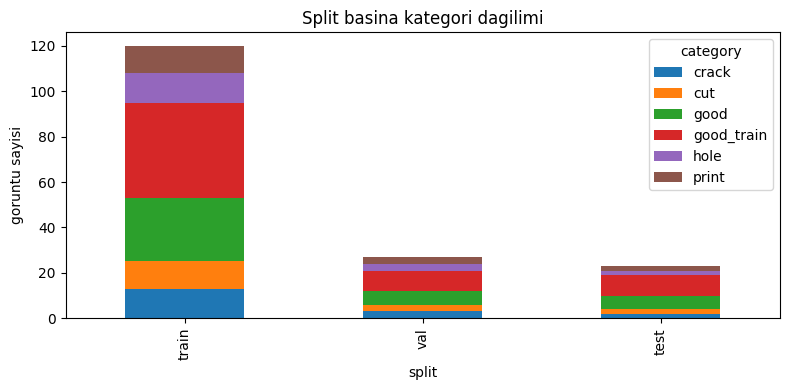

In [2]:
counts = df.groupby(["split", "category"]).size().unstack(fill_value=0)
counts = counts.reindex(["train", "val", "test"])
print(counts)
counts.plot(kind="bar", stacked=True, figsize=(8, 4), title="Split basina kategori dagilimi")
plt.ylabel("goruntu sayisi")
plt.tight_layout()
plt.show()

## Goruntu boyutu

MVTec AD hazelnut kategorisindeki tum goruntuler ayni cozunurlukte mi kontrol edilir (augmentation/resize stratejisini etkiler).

In [3]:
print("Benzersiz goruntu boyutlari (W, H):", stats["image_sizes"]["unique_sizes"])

Benzersiz goruntu boyutlari (W, H): [[1024, 1024]]


## Maske piksel dagilimi (class imbalance)

Kusurlu piksel orani (maskedeki pozitif piksel / toplam piksel) her kusurlu goruntu icin hesaplanir. Bu oranin kucuk olmasi, egitimde salt BCE yerine Dice/Combo loss kullanma kararini destekler.

Ozet istatistik (tum kusurlu maskeler uzerinden):
{
  "mean": 0.033546366010393416,
  "min": 0.0023288726806640625,
  "max": 0.27658557891845703,
  "n_defective_masks": 70
}


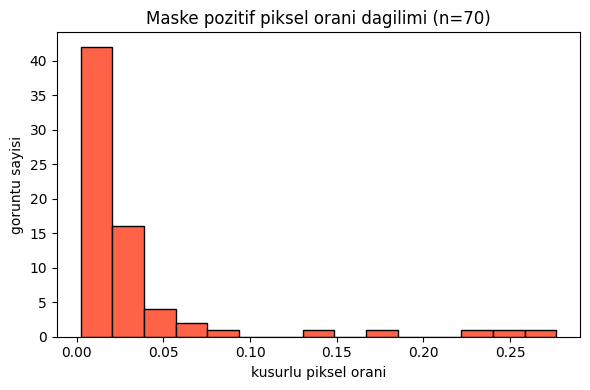

In [4]:
print("Ozet istatistik (tum kusurlu maskeler uzerinden):")
print(json.dumps(stats["mask_positive_pixel_ratio"], indent=2))

ratios = []
for _, row in df.dropna(subset=["mask_path"]).iterrows():
    if not isinstance(row["mask_path"], str) or not row["mask_path"]:
        continue
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    ratios.append((mask > 127).mean())

plt.figure(figsize=(6, 4))
plt.hist(ratios, bins=15, color="tomato", edgecolor="black")
plt.xlabel("kusurlu piksel orani")
plt.ylabel("goruntu sayisi")
plt.title(f"Maske pozitif piksel orani dagilimi (n={len(ratios)})")
plt.tight_layout()
plt.show()

## Ornek goruntu + maske

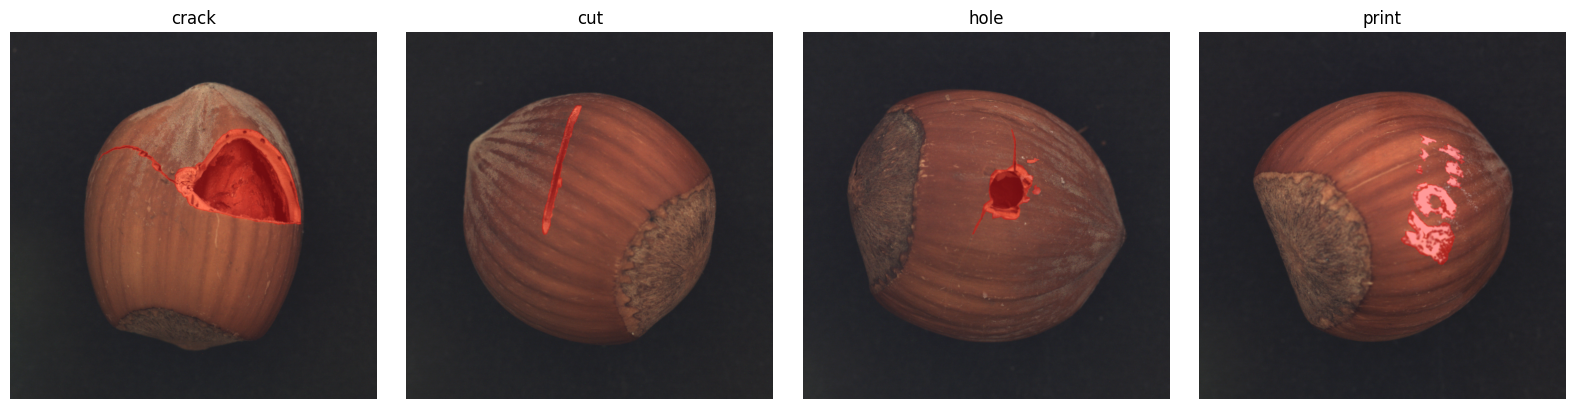

In [5]:
defect_rows = df[df["category"].isin(["crack", "cut", "hole", "print"])].groupby("category").first()

fig, axes = plt.subplots(1, len(defect_rows), figsize=(4 * len(defect_rows), 4))
for ax, (category, row) in zip(axes, defect_rows.iterrows()):
    image = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    overlay = image.copy()
    overlay[mask > 127] = [255, 0, 0]
    blended = cv2.addWeighted(image, 0.6, overlay, 0.4, 0)
    ax.imshow(blended)
    ax.set_title(category)
    ax.axis("off")
plt.tight_layout()
plt.show()